# ODP Site 1262 — Isotope Dataset Audit

## Research objective
Inspect the original isotope dataset, identify its structure,
assess missing values and data quality, and prepare a reproducible
dataset for subsequent PETM statistical analysis.

## Data source
Barnet et al. (2019), PANGAEA.
DOI: https://doi.org/10.1594/PANGAEA.903507

## Important
The raw dataset is preserved without modification.

Import Python libraries and locate the file

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Find the repository root from the notebook's working directory.
cwd = Path.cwd()

if (cwd / "data" / "raw").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot locate data/raw. Open the repository in VS Code "
        "and check the notebook working directory."
    )

raw_file = (
    project_root
    / "data"
    / "raw"
    / "208-1262_isotope.tab.tsv"
)

print("Project folder:", project_root)
print("File exists:", raw_file.exists())

Project folder: c:\MPHIL work\paleocene eocene plaeoclimate statistics\paleocene-eocene-paleoclimate-statistics
File exists: True


Inspect the metadata header

In [2]:
with raw_file.open(
    "r",
    encoding="utf-8-sig",
    errors="replace"
) as file:
    for line_number, line in enumerate(file, start=1):
        print(f"{line_number:03d}: {line.rstrip()}")

        if line_number >= 45:
            break

001: /* DATA DESCRIPTION:
002: Citation:	Barnet, James S K; Littler, Kate; Westerhold, Thomas; Kroon, Dick; Leng, Melanie J; Bailey, Ian; Röhl, Ursula; Zachos, James C (2019): Late Maastrichtian-early Eocene bulk sediment stable carbon and oxygen isotope records from ODP Site 208-1262, South Atlantic [dataset]. PANGAEA, https://doi.org/10.1594/PANGAEA.903507,
003: 	In supplement to: Barnet, JSK et al. (2019): A High-Fidelity Benthic Stable Isotope Record of Late Cretaceous–Early Eocene Climate Change and Carbon-Cycling. Paleoceanography and Paleoclimatology, 34(4), 672-691, https://doi.org/10.1029/2019PA003556
004: Related to:	Kroon, Dick; Zachos, James C; ODP Leg 208 Shipboard Scientific Party (2007): Leg 208 synthesis: Cenozoic climate cycles and excursions. In: Kroon, D.; Zachos, J.C.; Richter, C. (eds.), Proceedings of the Ocean Drilling Program, 208 Scientific Results, Proceedings of the Ocean Drilling Program, 208, Ocean Drilling Program, 208, 1-55, https://doi.org/10.2973/odp.pr

Identify where the numerical table begins

In [3]:
with raw_file.open(
    "r",
    encoding="utf-8-sig",
    errors="replace"
) as file:
    lines = file.readlines()

end_metadata = next(
    (
        i for i, line in enumerate(lines)
        if line.strip() == "*/"
    ),
    None
)

if end_metadata is None:
    raise ValueError(
        "PANGAEA metadata terminator */ was not found. "
        "Inspect the file format manually."
    )

header_index = end_metadata + 1

print("Metadata ends at line:", end_metadata + 1)
print("Expected column header:", lines[header_index].strip())

Metadata ends at line: 20
Expected column header: Depth sed [m]	δ13C bulk carb [‰ PDB]	δ18O bulk carb [‰ PDB]	Age [ka BP]	Reference


Load the table into pandas

In [4]:
df_raw = pd.read_csv(
    raw_file,
    sep="\t",
    skiprows=header_index,
    low_memory=False
)

print("Dataset shape:", df_raw.shape)

display(df_raw.head())

Dataset shape: (4364, 5)


,Depth sed [m],δ13C bulk carb [‰ PDB],δ18O bulk carb [‰ PDB],Age [ka BP],Reference
0,107.49,1.227,-0.607,52905,Zachos et al. (2010)
1,107.50,1.381,-0.473,52907,Zachos et al. (2010)
2,107.51,1.253,-0.551,52909,Zachos et al. (2010)
3,107.54,1.277,-0.427,52916,Zachos et al. (2010)
4,107.55,1.282,-0.428,52918,Zachos et al. (2010)


Inspect column names and data types

In [5]:
print("COLUMN NAMES")

for number, column in enumerate(df_raw.columns, start=1):
    print(f"{number}. {column}")

print("\nDATA TYPES")
print(df_raw.dtypes)

print("\nDATASET INFORMATION")
df_raw.info()

COLUMN NAMES
1. Depth sed [m]
2. δ13C bulk carb [‰ PDB]
3. δ18O bulk carb [‰ PDB]
4. Age [ka BP]
5. Reference

DATA TYPES
Depth sed [m]             float64
δ13C bulk carb [‰ PDB]    float64
δ18O bulk carb [‰ PDB]    float64
Age [ka BP]                 int64
Reference                  object
dtype: object

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4364 entries, 0 to 4363
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Depth sed [m]           4364 non-null   float64
 1   δ13C bulk carb [‰ PDB]  4363 non-null   float64
 2   δ18O bulk carb [‰ PDB]  4361 non-null   float64
 3   Age [ka BP]             4364 non-null   int64  
 4   Reference               4364 non-null   object 
dtypes: float64(3), int64(1), object(1)
memory usage: 170.6+ KB


Audit missing values and duplicate records

In [9]:
audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_missing": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
    "missing_percent": (
        df_raw.isna().mean() * 100
    ).round(2),
    "unique_values": df_raw.nunique(dropna=True)
})

display(audit)

print(
    "Exactly duplicated rows:",
    df_raw.duplicated().sum()
)

,dtype,non_missing,missing,missing_percent,unique_values
Depth sed [m],float64,4364,0,0.00,4315
δ13C bulk carb [‰ PDB],float64,4363,1,0.02,2170
δ18O bulk carb [‰ PDB],float64,4361,3,0.07,1073
Age [ka BP],int64,4364,0,0.00,4271
Reference,object,4364,0,0.00,5


Exactly duplicated rows: 0


Identify the isotope and age columns

In [6]:
for column in df_raw.columns:
    print(repr(column))

'Depth sed [m]'
'δ13C bulk carb [‰ PDB]'
'δ18O bulk carb [‰ PDB]'
'Age [ka BP]'
'Reference'


In [10]:
# Depth_col = "Depth sed [m]"
# Age_col = "Age [ka BP]"
# carbon_col = "δ13C bulk carb [‰ PDB]"
# oxygen_col = "δ18O bulk carb [‰ PDB]"
# Ref_col = "Reference"

Document what you found

## Initial data audit

### File provenance
- Data source: Barnet et al. (2019), PANGAEA
- Dataset DOI: https://doi.org/10.1594/PANGAEA.903507
- Raw file: data/raw/208-1262_isotope.tab.tsv
- Data type: Bulk carbonate stable carbon and oxygen isotope records

### Observed dataset structure
- Number of records: [4364]
- Number of variables: [5]
- Age column: [Age [ka BP]]
- Depth column: [Depth sed [m]]
- Carbon isotope column: [δ13C bulk carb [‰ PDB]]
- Oxygen isotope column: [δ18O bulk carb [‰ PDB]]
- Reference: [Reference]

### Quality-control observations
- Missing values: [4]
- Duplicate rows: [0]
- Metadata and units: [19]
- Issues requiring investigation: [6]
*Verify the number and distribution of complete δ¹³C–δ¹⁸O observation pairs.
Examine age–depth monotonicity and identify potential reversals.
Investigate repeated depths or ages and determine whether they represent valid observations.
Inspect the distribution of values in the Reference column.
Check for potential numerical outliers without automatically removing them.
Confirm the age-model description, isotope methods and reference-standard notation against the original metadata.*

### Processing policy
Raw measurements will be retained unchanged. Any filtering,
numeric conversion, age-model modification, or exclusion will
be documented before statistical analysis.

Show me the actual column names

In [11]:
print("DATASET SHAPE:", df_raw.shape)

print("\nCOLUMN NAMES:")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i}. {repr(col)}")

print("\nFIRST THREE RECORDS:")
display(df_raw.head(3))

DATASET SHAPE: (4364, 5)

COLUMN NAMES:
1. 'Depth sed [m]'
2. 'δ13C bulk carb [‰ PDB]'
3. 'δ18O bulk carb [‰ PDB]'
4. 'Age [ka BP]'
5. 'Reference'

FIRST THREE RECORDS:


,Depth sed [m],δ13C bulk carb [‰ PDB],δ18O bulk carb [‰ PDB],Age [ka BP],Reference
0,107.49,1.227,-0.607,52905,Zachos et al. (2010)
1,107.50,1.381,-0.473,52907,Zachos et al. (2010)
2,107.51,1.253,-0.551,52909,Zachos et al. (2010)


Learn about missing isotope measurements

In [12]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (
        df_raw.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

,missing_count,missing_percent
Depth sed [m],0,0.00
δ13C bulk carb [‰ PDB],1,0.02
δ18O bulk carb [‰ PDB],3,0.07
Age [ka BP],0,0.00
Reference,0,0.00


Check for duplicate observations

In [13]:
duplicate_count = df_raw.duplicated().sum()

print("Exactly duplicated rows:", duplicate_count)

Exactly duplicated rows: 0


In [14]:
# Identify the original columns
depth_col = "Depth sed [m]"
age_col = "Age [ka BP]"
carbon_col = "δ13C bulk carb [‰ PDB]"
oxygen_col = "δ18O bulk carb [‰ PDB]"

# Create a separate working DataFrame
df = df_raw.copy()

# Convert age from thousands to millions of years
df["age_ma"] = df[age_col] / 1000

# Identify observations containing both isotope measurements
paired = df.dropna(
    subset=[carbon_col, oxygen_col]
)

print("Total observations:", len(df))
print("Complete isotope pairs:", len(paired))
print("Missing carbon isotope values:", df[carbon_col].isna().sum())
print("Missing oxygen isotope values:", df[oxygen_col].isna().sum())

# Show rows containing missing isotope measurements
display(
    df.loc[
        df[[carbon_col, oxygen_col]].isna().any(axis=1),
        [depth_col, age_col, carbon_col, oxygen_col, "Reference"]
    ]
)

Total observations: 4364
Complete isotope pairs: 4360
Missing carbon isotope values: 1
Missing oxygen isotope values: 3


,Depth sed [m],Age [ka BP],δ13C bulk carb [‰ PDB],δ18O bulk carb [‰ PDB],Reference
2994,196.05,62205,2.479,NaN,Kroon et al. (2007)
3077,198.60,62540,NaN,-0.357,Kroon et al. (2007)
3852,219.70,66208,3.296,NaN,Kroon et al. (2007)
4354,235.80,67084,3.177,NaN,Kroon et al. (2007)


check the age–depth relationship

In [15]:
# Sort observations by increasing depth
depth_sorted = df.sort_values(depth_col).copy()

# Calculate the difference in age between adjacent records
depth_sorted["age_difference_ka"] = (
    depth_sorted[age_col].diff()
)

# Flag records where age becomes younger at greater depth
reversals = depth_sorted[
    depth_sorted["age_difference_ka"] < 0
]

print("Potential age-depth reversals:", len(reversals))

display(
    reversals[
        [depth_col, age_col, "age_difference_ka"]
    ]
)

Potential age-depth reversals: 1


,Depth sed [m],Age [ka BP],age_difference_ka
1826,158.66,57520,-1.0


Investigate the flagged records

In [16]:
# Examine the records surrounding the flagged reversal

near_reversal = depth_sorted[
    depth_sorted[depth_col].between(158.55, 158.75)
]

display(
    near_reversal[
        [
            depth_col,
            age_col,
            "age_ma",
            carbon_col,
            oxygen_col,
            "age_difference_ka"
        ]
    ]
)

,Depth sed [m],Age [ka BP],age_ma,δ13C bulk carb [‰ PDB],δ18O bulk carb [‰ PDB],age_difference_ka
1823,158.57,57515,57.515,3.580,-0.227,7.0
1824,158.60,57518,57.518,3.612,-0.262,3.0
1825,158.63,57521,57.521,3.661,-0.328,3.0
1826,158.66,57520,57.520,3.633,-0.384,-1.0
1827,158.70,57524,57.524,3.581,-0.314,4.0
1828,158.73,57526,57.526,3.507,-0.353,2.0


In [17]:
repeated_depths = df[
    df.duplicated(subset=[depth_col], keep=False)
]

print("Rows with repeated depths:", len(repeated_depths))
print(
    "Number of distinct repeated depths:",
    repeated_depths[depth_col].nunique()
)

display(repeated_depths.head(10))

Rows with repeated depths: 98
Number of distinct repeated depths: 49


,Depth sed [m],δ13C bulk carb [‰ PDB],δ18O bulk carb [‰ PDB],Age [ka BP],Reference,age_ma
360,117.07,0.873,-0.903,54043,Lourens et al. (2005),54.043
361,117.07,0.890,-0.830,54043,Lourens et al. (2005),54.043
362,117.08,0.841,-0.916,54043,Lourens et al. (2005),54.043
363,117.08,0.827,-0.798,54044,Lourens et al. (2005),54.044
364,117.09,0.790,-0.835,54044,Lourens et al. (2005),54.044
365,117.09,0.858,-0.862,54045,Lourens et al. (2005),54.045
366,117.10,0.762,-0.955,54045,Lourens et al. (2005),54.045
367,117.10,0.679,-0.862,54046,Lourens et al. (2005),54.046
368,117.11,0.645,-0.963,54046,Lourens et al. (2005),54.046
369,117.11,0.624,-0.932,54047,Lourens et al. (2005),54.047


### Age–depth consistency assessment

A preliminary age–depth monotonicity test identified one negative age increment in the ODP Site 1262 dataset. The flagged observation occurs at a sediment depth of 158.66 m and has a reported age of 57,520 ka BP (57.520 Ma). The difference relative to the preceding depth-sorted observation is −1 ka.

This represents a minor departure from the expected increase in depositional age with depth. The cause has not yet been established and may relate to the published age model, rounding, or other data characteristics.

The original age assignment has been retained without modification. The surrounding records and potential repeated-depth observations will be examined before determining whether further action is warranted.

The flagged observation lies outside the principal PETM-focused analysis interval near 55.9 Ma.

In [18]:
# Summarize repeated-depth observations
repeat_summary = (
    repeated_depths
    .groupby(depth_col)
    .agg(
        n_observations=(age_col, "size"),
        n_unique_ages=(age_col, "nunique"),
        carbon_min=(carbon_col, "min"),
        carbon_max=(carbon_col, "max"),
        oxygen_min=(oxygen_col, "min"),
        oxygen_max=(oxygen_col, "max")
    )
    .reset_index()
)

repeat_summary["carbon_range"] = (
    repeat_summary["carbon_max"]
    - repeat_summary["carbon_min"]
)

repeat_summary["oxygen_range"] = (
    repeat_summary["oxygen_max"]
    - repeat_summary["oxygen_min"]
)

print("Depth range of repeated observations:")
print(
    repeated_depths[depth_col].min(),
    "to",
    repeated_depths[depth_col].max(),
    "m"
)

print(
    "Repeated depths with different ages:",
    (repeat_summary["n_unique_ages"] > 1).sum()
)

display(repeat_summary.head(10))

Depth range of repeated observations:
117.07 to 215.23 m
Repeated depths with different ages: 24


,Depth sed [m],n_observations,n_unique_ages,carbon_min,carbon_max,oxygen_min,oxygen_max,carbon_range,oxygen_range
0,117.07,2,1,0.873,0.890,-0.903,-0.830,0.017,0.073
1,117.08,2,2,0.827,0.841,-0.916,-0.798,0.014,0.118
2,117.09,2,2,0.790,0.858,-0.862,-0.835,0.068,0.027
3,117.10,2,2,0.679,0.762,-0.955,-0.862,0.083,0.093
4,117.11,2,2,0.624,0.645,-0.963,-0.932,0.021,0.031
5,117.12,2,1,0.753,0.893,-1.008,-0.895,0.140,0.113
6,117.13,2,1,0.730,0.766,-0.951,-0.933,0.036,0.018
7,117.14,2,1,0.687,0.716,-0.985,-0.980,0.029,0.005
8,117.15,2,1,0.691,0.832,-0.908,-0.762,0.141,0.146
9,117.16,2,1,0.560,0.623,-0.883,-0.865,0.063,0.018


# Create a full-record carbon isotope plot

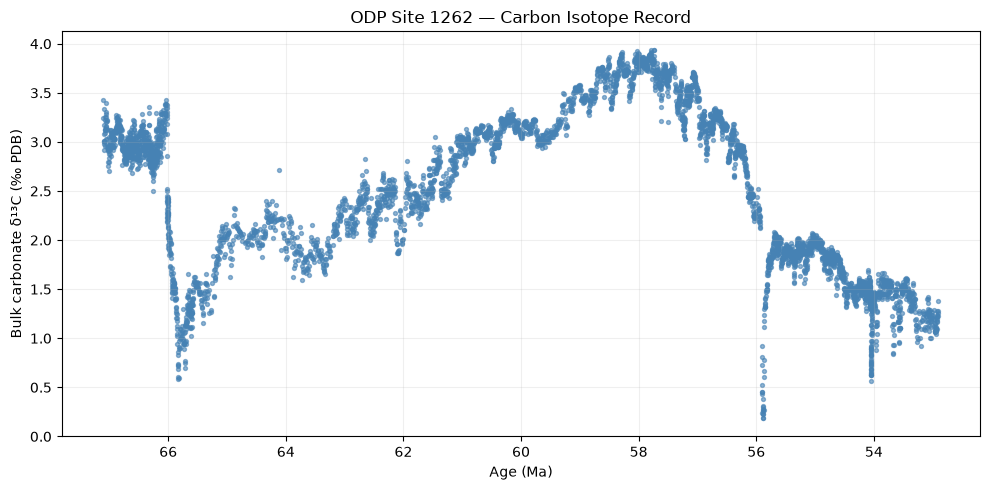

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    df["age_ma"],
    df[carbon_col],
    s=8,
    alpha=0.6,
    color="steelblue"
)

ax.invert_xaxis()

ax.set_xlabel("Age (Ma)")
ax.set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
ax.set_title("ODP Site 1262 — Carbon Isotope Record")

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Plot carbon and oxygen isotopes together

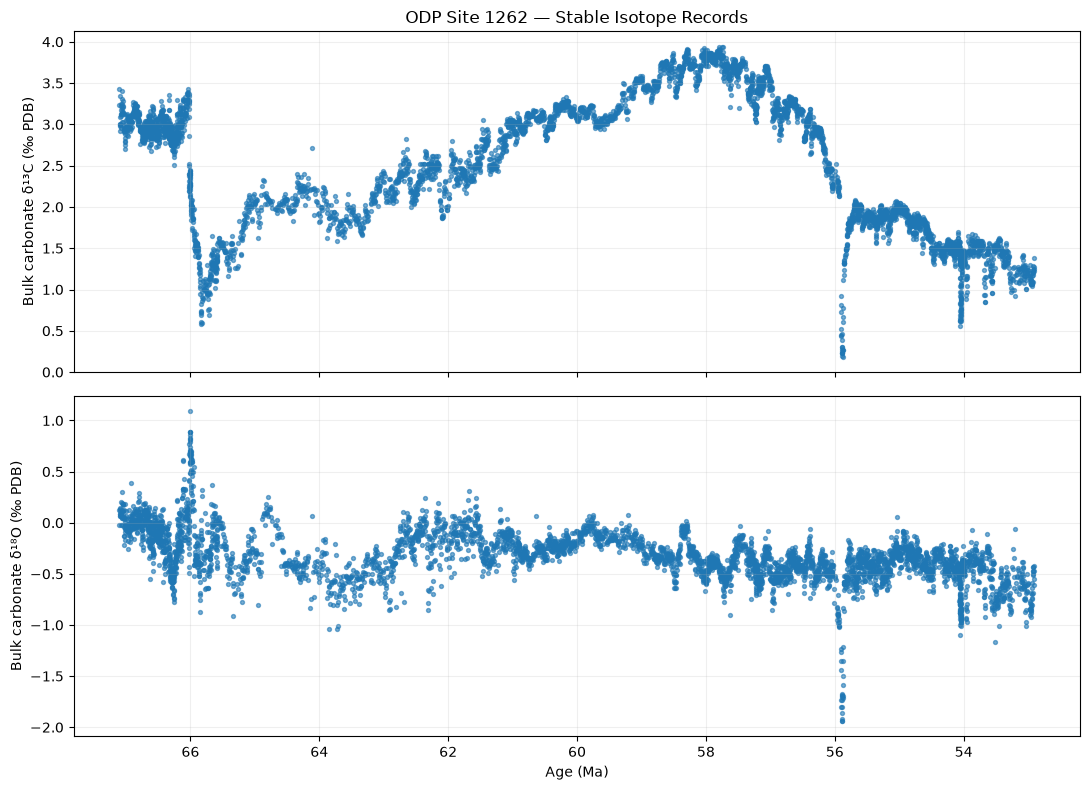

In [20]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

axes[0].scatter(
    df["age_ma"],
    df[carbon_col],
    s=8,
    alpha=0.6
)

axes[0].set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
axes[0].set_title("ODP Site 1262 — Stable Isotope Records")
axes[0].grid(alpha=0.2)

axes[1].scatter(
    df["age_ma"],
    df[oxygen_col],
    s=8,
    alpha=0.6
)

axes[1].set_ylabel("Bulk carbonate δ¹⁸O (‰ PDB)")
axes[1].set_xlabel("Age (Ma)")
axes[1].grid(alpha=0.2)

axes[1].invert_xaxis()

plt.tight_layout()
plt.show()

Zoom into the PETM interval

Observations in selected interval: 324


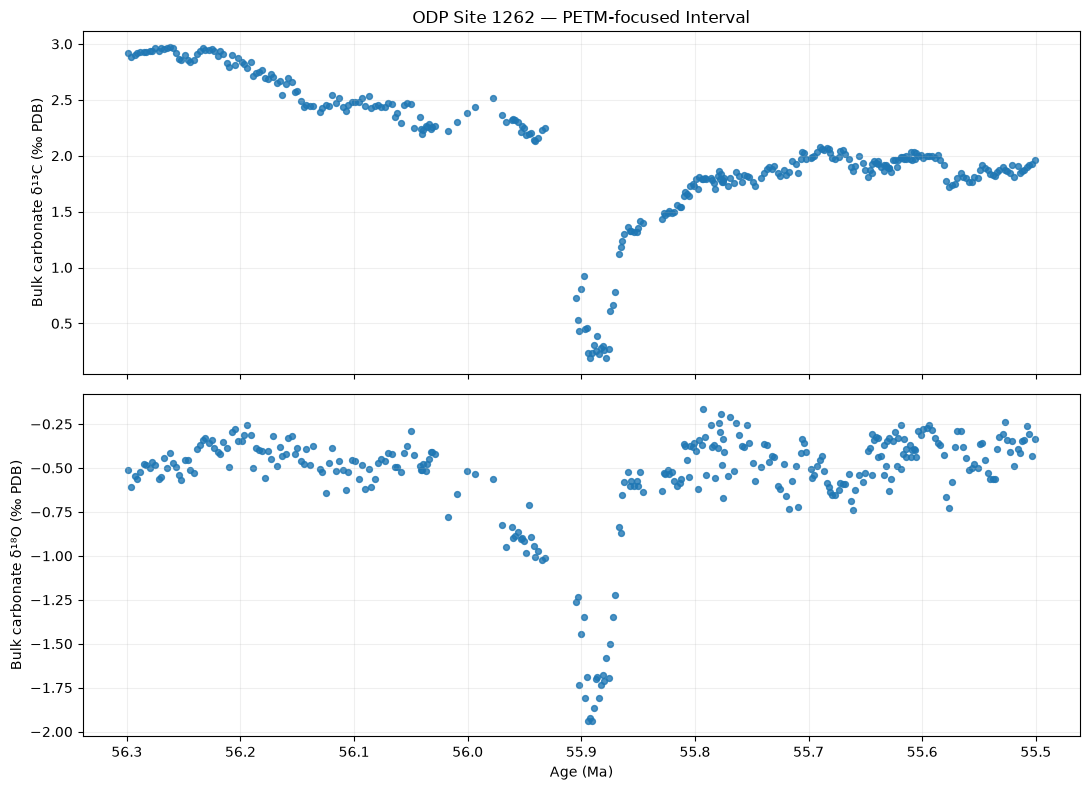

In [21]:
petm_window = df[
    df["age_ma"].between(55.5, 56.3)
].copy()

print(
    "Observations in selected interval:",
    len(petm_window)
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

axes[0].scatter(
    petm_window["age_ma"],
    petm_window[carbon_col],
    s=18,
    alpha=0.8
)

axes[0].set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
axes[0].set_title(
    "ODP Site 1262 — PETM-focused Interval"
)
axes[0].grid(alpha=0.2)

axes[1].scatter(
    petm_window["age_ma"],
    petm_window[oxygen_col],
    s=18,
    alpha=0.8
)

axes[1].set_ylabel("Bulk carbonate δ¹⁸O (‰ PDB)")
axes[1].set_xlabel("Age (Ma)")
axes[1].grid(alpha=0.2)

axes[1].invert_xaxis()

plt.tight_layout()
plt.show()

### Age–depth and repeated-depth assessment

The age–depth consistency assessment identified one local age reversal between 158.63 and 158.66 m, where the reported age decreases from 57.521 to 57.520 Ma. The discrepancy is equivalent to 1 ka and occurs over 0.03 m of sediment depth.

The dataset also contains 98 observations associated with 49 repeated depth values. The repeated observations are not necessarily erroneous, as isotope values can differ between records sharing the same reported depth. Their origin and analytical independence require verification against the source metadata.

All observations and original age assignments have been retained. No age correction, averaging, interpolation, or deletion has been performed.

Subsequent analyses will consider the potential effects of repeated-depth measurements and age-model uncertainties on statistical independence and temporal interpretation.